# Clase 7 — Modelos no supervisados

## Objetivo

Aplicar técnicas de aprendizaje no supervisado para identificar agrupaciones
en los datos de sensores utilizando K-Means y DBSCAN.

## Modelos utilizados

- K-Means
- DBSCAN

## Evaluación

Se utilizará el método del codo para seleccionar el número de clusters
en K-Means y el Silhouette Score para evaluar la calidad de las agrupaciones.

## 1. Preparación de los datos

El dataset contiene 5456 observaciones y 24 variables correspondientes
a los sensores US1–US24.

Para el aprendizaje no supervisado no se utiliza la variable objetivo
para formar los clusters.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

In [2]:
# Cargar dataset procesado
dataset = pd.read_parquet(
    "../data/processed/dataset.parquet"
)

print("Dataset cargado correctamente.")
print("Tamaño:", dataset.shape)

Dataset cargado correctamente.
Tamaño: (5456, 26)


In [3]:
# Seleccionar únicamente las variables de los sensores
sensor_columns = [f"US{i}" for i in range(1, 25)]

X = dataset[sensor_columns]

print("Variables utilizadas:")
print(X.columns.tolist())

print("\nTamaño de X:")
print(X.shape)

Variables utilizadas:
['US1', 'US2', 'US3', 'US4', 'US5', 'US6', 'US7', 'US8', 'US9', 'US10', 'US11', 'US12', 'US13', 'US14', 'US15', 'US16', 'US17', 'US18', 'US19', 'US20', 'US21', 'US22', 'US23', 'US24']

Tamaño de X:
(5456, 24)


## 2. Selección del número de clusters — Método del codo

El método del codo permite analizar diferentes valores de `k` y observar
cómo disminuye la inercia del modelo K-Means.

La inercia representa la suma de las distancias cuadráticas entre cada
observación y el centroide de su cluster.

Se selecciona un valor de `k` cercano al punto donde la disminución de
la inercia comienza a ser menos pronunciada.

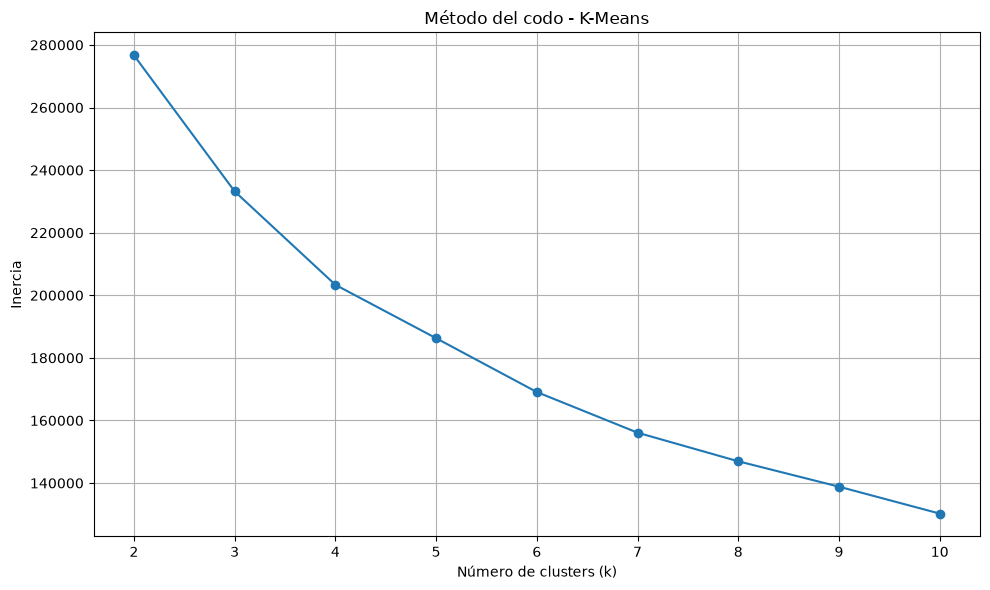

In [4]:
# Método del codo

inercia = []
valores_k = range(2, 11)

for k in valores_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    modelo.fit(X)

    inercia.append(modelo.inertia_)

plt.figure(figsize=(10, 6))

plt.plot(
    valores_k,
    inercia,
    marker="o"
)

plt.title("Método del codo - K-Means")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.grid(True)
plt.tight_layout()
plt.show()

### Selección de k

A partir de la gráfica del método del codo se selecciona `k = 4`, debido a
que a partir de este valor la reducción de la inercia comienza a ser menos
pronunciada.

In [5]:
k_optimo = 4

print("Número de clusters seleccionado:", k_optimo)

Número de clusters seleccionado: 4


## 3. Entrenamiento de K-Means

Se entrena el algoritmo K-Means utilizando el valor `k = 4` seleccionado
mediante el método del codo.

In [6]:
# Entrenamiento de K-Means

modelo_kmeans = KMeans(
    n_clusters=k_optimo,
    random_state=42,
    n_init=10
)

modelo_kmeans.fit(X)

print("K-Means entrenado correctamente.")
print("Clusters encontrados:", modelo_kmeans.n_clusters)

K-Means entrenado correctamente.
Clusters encontrados: 4


## 4. Evaluación de K-Means — Silhouette Score

El Silhouette Score permite evaluar la calidad de la separación de los
clusters.

Su valor se encuentra entre -1 y 1. Valores cercanos a 1 indican una
mejor separación entre los grupos.

In [7]:
# Evaluación mediante Silhouette Score

silhouette_kmeans = silhouette_score(
    X,
    modelo_kmeans.labels_
)

print(
    "Silhouette Score K-Means:",
    round(silhouette_kmeans, 4)
)

Silhouette Score K-Means: 0.4702


## 5. Visualización de los clusters mediante PCA

El dataset contiene 24 variables correspondientes a los sensores ultrasónicos,
por lo que no es posible visualizar directamente los datos en un plano.

Se utiliza PCA (Análisis de Componentes Principales) para reducir
temporalmente las 24 dimensiones a 2 componentes y representar
gráficamente los clusters encontrados por K-Means.

La reducción mediante PCA se utiliza únicamente para visualización.
El modelo K-Means fue entrenado utilizando las 24 variables originales.

In [8]:
# Reducción a 2 componentes mediante PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print("Dimensiones originales:", X.shape)
print("Dimensiones después de PCA:", X_pca.shape)

print(
    "Varianza explicada por los componentes:",
    pca.explained_variance_ratio_
)

print(
    "Varianza explicada acumulada:",
    pca.explained_variance_ratio_.sum()
)

Dimensiones originales: (5456, 24)
Dimensiones después de PCA: (5456, 2)
Varianza explicada por los componentes: [0.30281465 0.16874034]
Varianza explicada acumulada: 0.4715549929270092


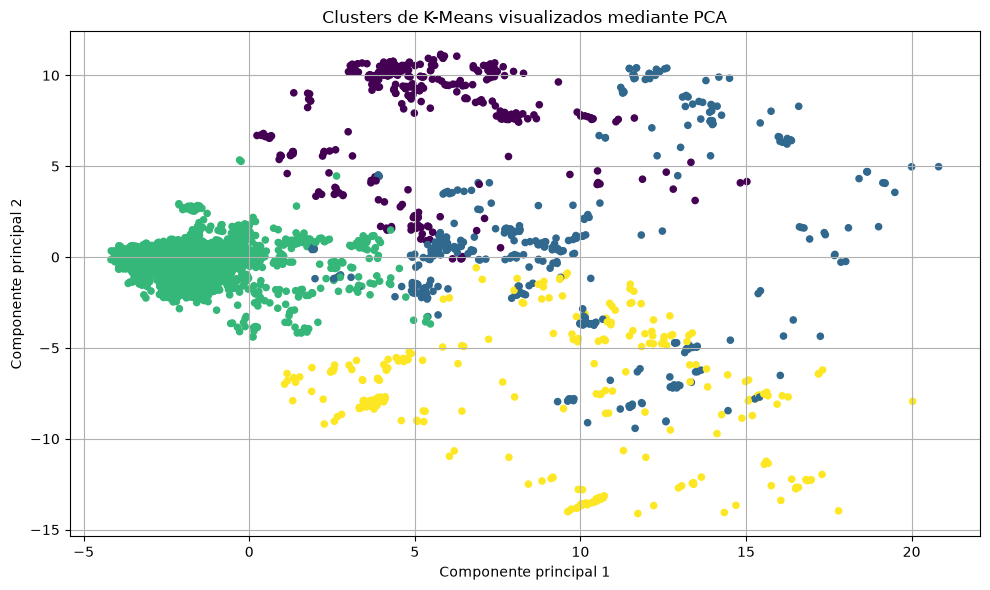

In [9]:
# Visualización de los clusters de K-Means

plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=modelo_kmeans.labels_,
    s=20
)

plt.title("Clusters de K-Means visualizados mediante PCA")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.grid(True)
plt.tight_layout()
plt.show()

## 6. Visualización mediante t-SNE

t-SNE (t-distributed Stochastic Neighbor Embedding) es una técnica de
reducción dimensional no lineal.

Su objetivo principal es representar en un espacio de menor dimensión
las relaciones de proximidad entre las observaciones.

En este proyecto se utilizará t-SNE para reducir las 24 variables de
los sensores a 2 dimensiones y visualizar la distribución de los datos.

La reducción dimensional se utiliza únicamente para visualización;
los modelos de clustering fueron entrenados utilizando las 24 variables
originales.

In [10]:
from sklearn.manifold import TSNE

# Reducir las 24 variables a 2 dimensiones mediante t-SNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    max_iter=1000,
    random_state=42
)

X_tsne = tsne.fit_transform(X)

print("Dimensiones originales:", X.shape)
print("Dimensiones después de t-SNE:", X_tsne.shape)

Dimensiones originales: (5456, 24)
Dimensiones después de t-SNE: (5456, 2)


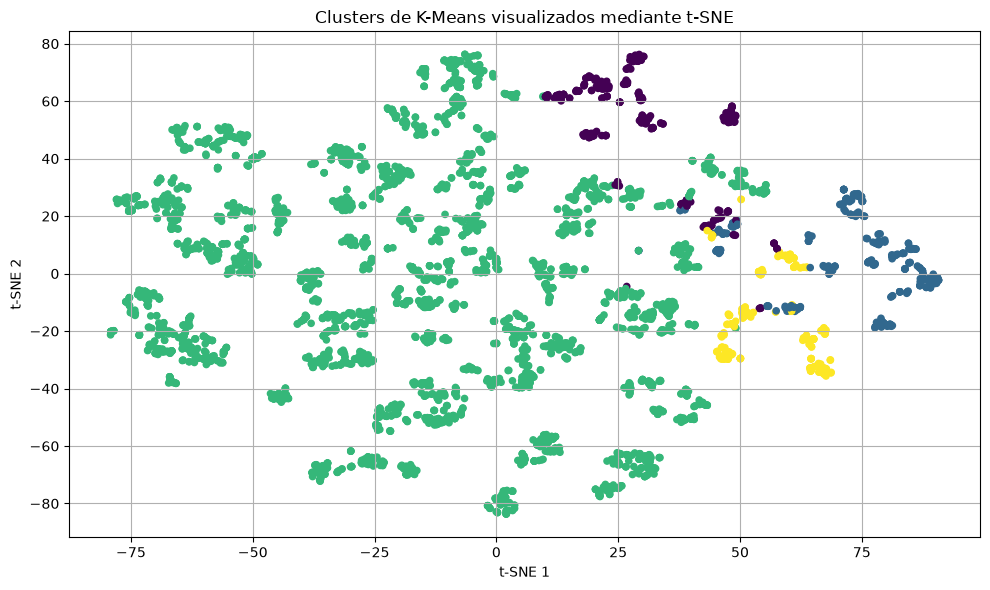

In [11]:
# Visualización de K-Means mediante t-SNE

plt.figure(figsize=(10, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=modelo_kmeans.labels_,
    s=20
)

plt.title("Clusters de K-Means visualizados mediante t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)
plt.tight_layout()
plt.show()

### Visualización de DBSCAN mediante t-SNE

Se utiliza la misma representación bidimensional obtenida mediante t-SNE
para visualizar las agrupaciones encontradas por DBSCAN.

DBSCAN permite además identificar observaciones consideradas como ruido,
representadas mediante la etiqueta `-1`.

In [12]:
# Entrenamiento de DBSCAN para la visualización

modelo_dbscan_final = DBSCAN(
    eps=5.0,
    min_samples=5
)

modelo_dbscan_final.fit(X)

print("DBSCAN entrenado correctamente.")
print("Clusters encontrados:",
      len(set(modelo_dbscan_final.labels_)) -
      (1 if -1 in modelo_dbscan_final.labels_ else 0))

print("Puntos de ruido:",
      list(modelo_dbscan_final.labels_).count(-1))

DBSCAN entrenado correctamente.
Clusters encontrados: 19
Puntos de ruido: 107


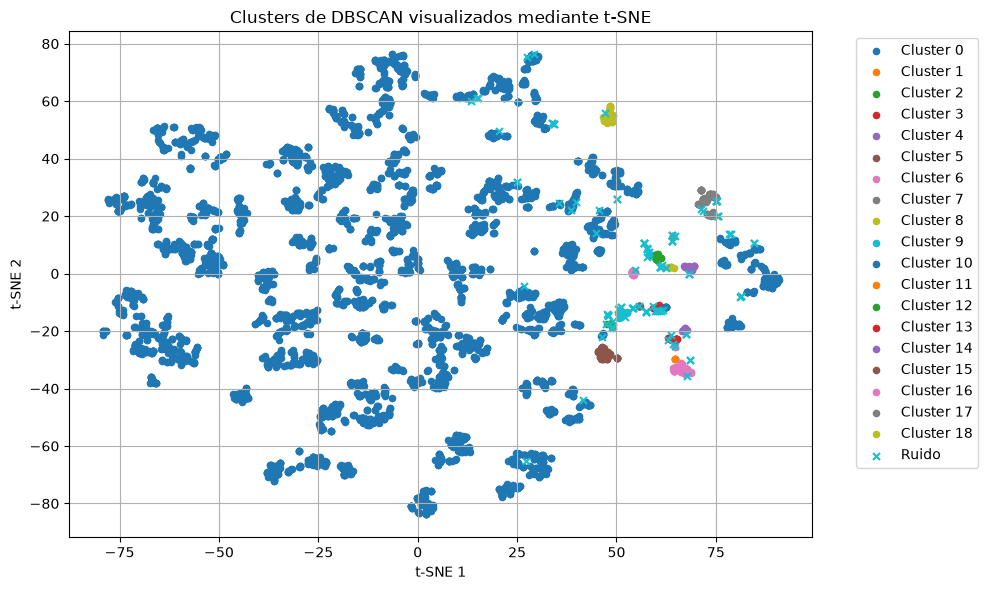

In [13]:

# Visualización de DBSCAN mediante t-SNE

plt.figure(figsize=(10, 6))

labels = modelo_dbscan_final.labels_

# Mostrar los clusters
clusters = sorted(set(labels) - {-1})

for cluster in clusters:
    mask = labels == cluster
    
    plt.scatter(
        X_tsne[mask, 0],
        X_tsne[mask, 1],
        s=20,
        label=f"Cluster {cluster}"
    )

# Mostrar el ruido por separado
ruido = labels == -1

plt.scatter(
    X_tsne[ruido, 0],
    X_tsne[ruido, 1],
    s=25,
    marker="x",
    label="Ruido"
)

plt.title("Clusters de DBSCAN visualizados mediante t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.grid(True)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 7. Comparación visual de K-Means y DBSCAN

La visualización mediante t-SNE permite observar diferencias entre las
agrupaciones obtenidas por ambos algoritmos.

K-Means genera cuatro grupos definidos previamente mediante el número de
clusters seleccionado. Por otro lado, DBSCAN identifica un mayor número
de agrupaciones y permite detectar observaciones consideradas como ruido.

La representación t-SNE facilita la observación de estructuras locales
en los datos, aunque la visualización no debe interpretarse como una
medida directa de la calidad del clustering.

En nuestro dataset, K-Means obtuvo un Silhouette Score de 0.4702,
mientras que DBSCAN obtuvo 0.4052. Por esta métrica, K-Means presenta
una mejor separación global de los clusters en este experimento.

## 8. Benchmark de latencia

Se medirá el tiempo promedio de inferencia de diferentes modelos
previamente entrenados.

Para cada modelo se realizarán 100 predicciones individuales y se
calculará la latencia promedio en milisegundos.

No se incluye el tiempo de entrenamiento dentro de esta medición.

In [14]:
import joblib
from pathlib import Path

# Localizar la carpeta models
base_dir = Path.cwd()

if not (base_dir / "models").exists() and (base_dir.parent / "models").exists():
    base_dir = base_dir.parent

models_dir = base_dir / "models"

# Guardar K-Means
joblib.dump(
    modelo_kmeans,
    models_dir / "kmeans.pkl"
)

print("K-Means guardado en:")
print(models_dir / "kmeans.pkl")

K-Means guardado en:
c:\Users\FABIA\OneDrive\Escritorio\ml-practica1-pesantez\models\kmeans.pkl


In [15]:
# Cargar modelos previamente entrenados

modelo_kmeans_cargado = joblib.load(
    models_dir / "kmeans.pkl"
)

modelo_rf = joblib.load(
    models_dir / "random_forest.pkl"
)

modelo_svm = joblib.load(
    models_dir / "svm.pkl"
)

print("Modelos cargados correctamente.")

Modelos cargados correctamente.


In [16]:
# Seleccionar 100 observaciones para el benchmark

X_benchmark = X[:100]

print("Muestras utilizadas:", X_benchmark.shape)

Muestras utilizadas: (100, 24)


In [17]:
import time
import numpy as np

def medir_latencia(modelo, X_datos, n_predicciones=100):
    tiempos = []

    # Predicción inicial para estabilizar la ejecución
    modelo.predict(X_datos[:1])

    for i in range(n_predicciones):
        muestra = X_datos[i:i+1]

        inicio = time.perf_counter()

        modelo.predict(muestra)

        fin = time.perf_counter()

        tiempos.append((fin - inicio) * 1000)

    return np.mean(tiempos)

In [18]:
# Seleccionar 100 observaciones para el benchmark

X_benchmark = X[:100]

print("Muestras utilizadas:", X_benchmark.shape)

Muestras utilizadas: (100, 24)


In [19]:
print("Midiendo latencia...")

latencia_kmeans = medir_latencia(
    modelo_kmeans_cargado,
    X_benchmark_df
)

latencia_rf = medir_latencia(
    modelo_rf,
    X_benchmark_np
)

latencia_svm = medir_latencia(
    modelo_svm,
    X_benchmark_np
)

print("\nRESULTADOS")
print(f"K-Means:       {latencia_kmeans:.4f} ms")
print(f"Random Forest: {latencia_rf:.4f} ms")
print(f"SVM:           {latencia_svm:.4f} ms")

Midiendo latencia...


NameError: name 'X_benchmark_df' is not defined

In [ ]:
print(type(X))

<class 'pandas.DataFrame'>


In [ ]:
print("Tipo de X_benchmark:", type(X_benchmark))
print("Número de columnas:", len(X_benchmark.columns))

print("\nPrimeras columnas de X:")
print(X.columns.tolist()[:5])

print("\nRandom Forest:")
print(hasattr(modelo_rf, "feature_names_in_"))

print("\nSVM:")
print(hasattr(modelo_svm, "feature_names_in_"))

print("\nK-Means:")
print(hasattr(modelo_kmeans_cargado, "feature_names_in_"))

Tipo de X_benchmark: <class 'pandas.DataFrame'>
Número de columnas: 24

Primeras columnas de X:
['US1', 'US2', 'US3', 'US4', 'US5']

Random Forest:
False

SVM:
False

K-Means:
True


In [ ]:
# Preparar los datos según el formato utilizado por cada modelo

X_benchmark_df = X.iloc[:100]

# Random Forest y SVM fueron entrenados sin nombres de columnas
X_benchmark_np = X_benchmark_df.to_numpy()

print("K-Means:", X_benchmark_df.shape)
print("Random Forest:", X_benchmark_np.shape)
print("SVM:", X_benchmark_np.shape)

K-Means: (100, 24)
Random Forest: (100, 24)
SVM: (100, 24)


In [ ]:
import json

benchmark = {
    "n_predicciones": 100,
    "unidad": "ms",
    "tipo": "latencia promedio de inferencia individual",
    "modelos": {
        "K-Means": round(float(latencia_kmeans), 4),
        "Random Forest": round(float(latencia_rf), 4),
        "SVM": round(float(latencia_svm), 4)
    }
}

benchmark_path = base_dir / "benchmark_latency.json"

with open(benchmark_path, "w", encoding="utf-8") as archivo:
    json.dump(
        benchmark,
        archivo,
        indent=4,
        ensure_ascii=False
    )

print("Benchmark guardado en:")
print(benchmark_path)

Benchmark guardado en:
c:\Users\FABIA\OneDrive\Escritorio\ml-practica1-pesantez\benchmark_latency.json
